# Stock Market Data Analysis and Visualization

## Project Overview

This project analyzes historical stock market data to identify trends and patterns in stock prices over time.

The analysis includes stock price trends, moving averages, trading volume, daily returns, volatility, distributions, outliers, correlations, and important market events.

The dataset is obtained from Yahoo Finance using the `yfinance` library.

### Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- yfinance

## Project Objective

The main objective of this project is to analyze historical stock market data and identify trends and patterns in stock prices over time.

The project also aims to:

- Analyze historical closing prices
- Calculate 20-day and 50-day moving averages
- Analyze trading volume
- Calculate daily returns
- Measure basic volatility
- Study the distribution of daily returns
- Identify possible outliers
- Analyze correlations between numerical variables
- Study the relationship between stock price and trading volume
- Identify important historical market events
- Present findings using professional visualizations

## Introduction

Stock market data contains information about how a stock's price and trading activity change over time.

In this project, historical Apple Inc. (AAPL) stock data is analyzed using Python.

Pandas is used for data manipulation and analysis, NumPy is used for numerical calculations, and Matplotlib and Seaborn are used for data visualization.

The analysis focuses on historical observations and does not attempt to predict future stock prices.

## Import Libraries

The required Python libraries are imported for data collection, data manipulation, numerical calculations, and visualization.

In [85]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Load Dataset

The historical stock price data is downloaded from Yahoo Finance using the `yfinance` library.

The selected stock is Apple Inc. (AAPL).

The analysis uses daily historical data from 2020 to 2025.

In [86]:
ticker = "AAPL"

df = yf.download(
    ticker,
    start="2020-01-01",
    end="2026-01-01",
    interval="1d",
    auto_adjust=False
)

print("Dataset loaded successfully.")
print("Number of rows:", len(df))

[*********************100%***********************]  1 of 1 completed


Dataset loaded successfully.
Number of rows: 1508


In [87]:
df.reset_index(inplace=True)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = [column[0] for column in df.columns]

print("Columns:")
print(df.columns.tolist())

Columns:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


## Dataset Overview

Before performing analysis, the structure and contents of the dataset are examined.

The first and last few records, number of rows and columns, column names, data types, and statistical summary are checked.

In [88]:
print("First 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nShape of dataset:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

First 5 rows:
        Date  Adj Close      Close       High        Low       Open     Volume
0 2020-01-02  72.271538  75.087502  75.150002  73.797501  74.059998  135480400
1 2020-01-03  71.568916  74.357498  75.144997  74.125000  74.287498  146322800
2 2020-01-06  72.139198  74.949997  74.989998  73.187500  73.447502  118387200
3 2020-01-07  71.799919  74.597504  75.224998  74.370003  74.959999  108872000
4 2020-01-08  72.954918  75.797501  76.110001  74.290001  74.290001  132079200

Last 5 rows:
           Date   Adj Close       Close        High         Low        Open  \
1503 2025-12-24  273.066711  273.809998  275.429993  272.200012  272.339996   
1504 2025-12-26  272.657806  273.399994  275.369995  272.859985  274.160004   
1505 2025-12-29  273.016876  273.760010  274.359985  272.350006  272.690002   
1506 2025-12-30  272.338684  273.079987  274.079987  272.279999  272.809998   
1507 2025-12-31  271.122009  271.859985  273.679993  271.750000  273.059998   

        Volume  
1503  

In [89]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype        
---  ------     --------------  -----        
 0   Date       1508 non-null   datetime64[s]
 1   Adj Close  1508 non-null   float64      
 2   Close      1508 non-null   float64      
 3   High       1508 non-null   float64      
 4   Low        1508 non-null   float64      
 5   Open       1508 non-null   float64      
 6   Volume     1508 non-null   int64        
dtypes: datetime64[s](1), float64(5), int64(1)
memory usage: 82.6 KB


In [90]:
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
                      Date    Adj Close        Close         High  \
count                 1508  1508.000000  1508.000000  1508.000000   
mean   2022-12-30 16:01:35   164.493894   167.061671   168.769448   
min    2020-01-02 00:00:00    54.117027    56.092499    57.125000   
25%    2021-06-30 18:00:00   131.065289   134.667500   136.004997   
50%    2022-12-28 12:00:00   162.903633   166.075005   167.869995   
75%    2024-07-01 06:00:00   197.028114   198.217495   200.130001   
max    2025-12-31 00:00:00   285.413116   286.190002   288.619995   
std                    NaN    49.583692    48.975039    49.254618   

               Low         Open        Volume  
count  1508.000000  1508.000000  1.508000e+03  
mean    165.185171   166.898548  8.453734e+07  
min      53.152500    57.020000  1.791060e+07  
25%     133.334999   134.797501  5.075645e+07  
50%     164.510002   166.049995  7.040210e+07  
75%     195.910000   197.795002  1.005718e+08  
max     283.299988   

In [91]:
df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Date data type:", df["Date"].dtype)
print("Starting Date:", df["Date"].min())
print("Ending Date:", df["Date"].max())

Date data type: datetime64[s]
Starting Date: 2020-01-02 00:00:00
Ending Date: 2025-12-31 00:00:00


## Data Cleaning

Data cleaning is performed to make sure the dataset is suitable for analysis.

The following checks are performed:

- Missing values
- Duplicate records
- Date format
- Sorting by date

In [92]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Duplicate Rows:
0


In [93]:
before_rows = len(df)

df = df.drop_duplicates()

df = df.dropna(subset=["Date", "Open", "High", "Low", "Close", "Volume"])

after_rows = len(df)

print("Rows before cleaning:", before_rows)
print("Rows after cleaning:", after_rows)
print("Rows removed:", before_rows - after_rows)

Rows before cleaning: 1508
Rows after cleaning: 1508
Rows removed: 0


In [94]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows After Cleaning:")
print(df.duplicated().sum())

Missing Values After Cleaning:
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Duplicate Rows After Cleaning:
0


## Preprocessing

Additional columns are created from the date column to support time-based analysis.

The year column will be used for yearly analysis.

In [95]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

print(df[["Date", "Year", "Month"]].head())

        Date  Year  Month
0 2020-01-02  2020      1
1 2020-01-03  2020      1
2 2020-01-06  2020      1
3 2020-01-07  2020      1
4 2020-01-08  2020      1


## Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the general behavior of the stock.

Basic numerical statistics such as mean, median, minimum, maximum, standard deviation, variance, and quantiles are calculated for the closing price.

In [96]:
close_price = df["Close"]

print("Mean Closing Price:", np.mean(close_price))
print("Median Closing Price:", np.median(close_price))
print("Minimum Closing Price:", np.min(close_price))
print("Maximum Closing Price:", np.max(close_price))
print("Standard Deviation:", np.std(close_price))
print("Variance:", np.var(close_price))

print("\n25% Quantile:", np.quantile(close_price, 0.25))
print("50% Quantile:", np.quantile(close_price, 0.50))
print("75% Quantile:", np.quantile(close_price, 0.75))

Mean Closing Price: 167.06167102682178
Median Closing Price: 166.07500457763672
Minimum Closing Price: 56.092498779296875
Maximum Closing Price: 286.19000244140625
Standard Deviation: 48.95879760810346
Variance: 2396.9638632312367

25% Quantile: 134.66749954223633
50% Quantile: 166.07500457763672
75% Quantile: 198.2174949645996


## NumPy Analysis

NumPy is used to convert the closing price data into an array and perform numerical operations.

This demonstrates NumPy array properties, indexing, slicing, mathematical operations, and statistical functions.

In [97]:
close_array = np.array(df["Close"])

print("Array:")
print(close_array[:10])

print("\nShape:", close_array.shape)
print("Size:", close_array.size)
print("Data Type:", close_array.dtype)

print("\nFirst Value:", close_array[0])
print("First 5 Values:", close_array[:5])

print("\nMean:", np.mean(close_array))
print("Median:", np.median(close_array))
print("Minimum:", np.min(close_array))
print("Maximum:", np.max(close_array))
print("Standard Deviation:", np.std(close_array))
print("Variance:", np.var(close_array))

Array:
[75.08750153 74.35749817 74.94999695 74.59750366 75.79750061 77.40750122
 77.58249664 79.23999786 78.16999817 77.83499908]

Shape: (1508,)
Size: 1508
Data Type: float64

First Value: 75.0875015258789
First 5 Values: [75.08750153 74.35749817 74.94999695 74.59750366 75.79750061]

Mean: 167.06167102682178
Median: 166.07500457763672
Minimum: 56.092498779296875
Maximum: 286.19000244140625
Standard Deviation: 48.95879760810346
Variance: 2396.9638632312367


## Stock Price Trend Analysis

The closing price is plotted against date to understand how the stock price changed over the selected historical period.

A line chart is suitable because the data is time-based.

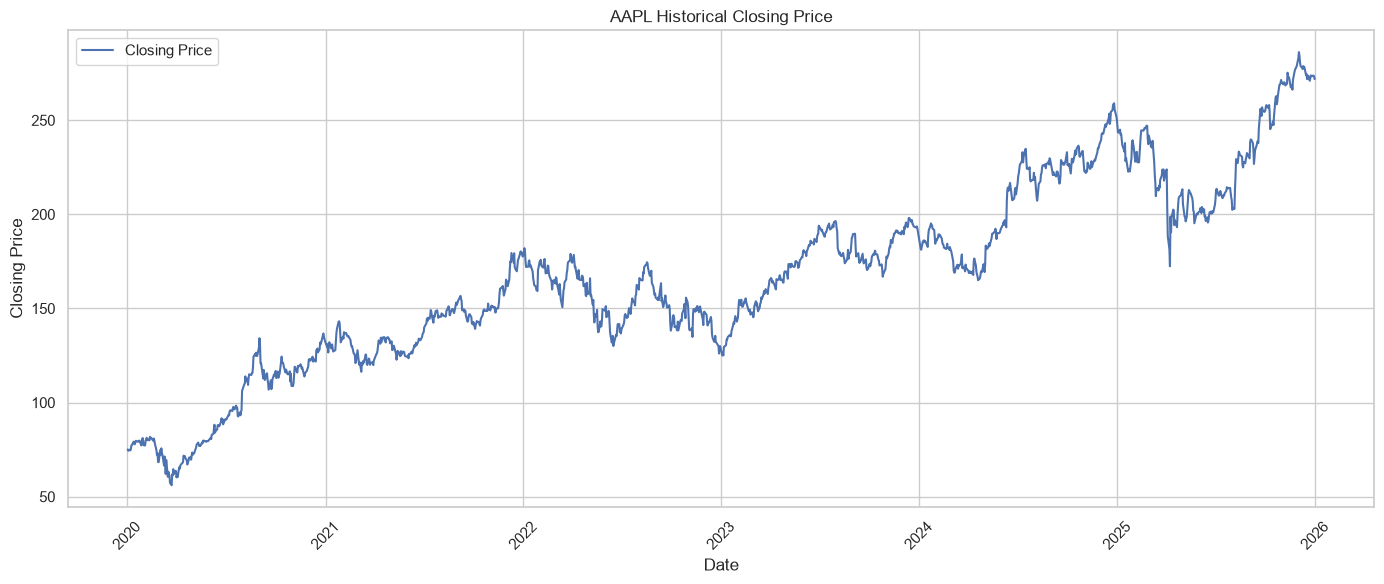

In [98]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"],
    label="Closing Price",
    linewidth=1.5
)

plt.title("AAPL Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [99]:
first_close = df.iloc[0]["Close"]
last_close = df.iloc[-1]["Close"]

percentage_change = ((last_close - first_close) / first_close) * 100

print("First Closing Price:", round(first_close, 2))
print("Last Closing Price:", round(last_close, 2))
print("Overall Percentage Change:", round(percentage_change, 2), "%")

if last_close > first_close:
    print("The closing price was higher at the end of the selected period than at the beginning.")
elif last_close < first_close:
    print("The closing price was lower at the end of the selected period than at the beginning.")
else:
    print("The closing price was unchanged between the beginning and end of the selected period.")

First Closing Price: 75.09
Last Closing Price: 271.86
Overall Percentage Change: 262.06 %
The closing price was higher at the end of the selected period than at the beginning.


## Moving Average Analysis

Moving averages are used to smooth short-term price fluctuations and observe the general direction of the stock price.

Two moving averages are calculated:

- 20-day moving average
- 50-day moving average

In [100]:
df["MA20"] = df["Close"].rolling(window=20).mean()
df["MA50"] = df["Close"].rolling(window=50).mean()

print(df[["Date", "Close", "MA20", "MA50"]].tail())

           Date       Close        MA20        MA50
1503 2025-12-24  273.809998  277.151999  271.046599
1504 2025-12-26  273.399994  276.944499  271.527799
1505 2025-12-29  273.760010  276.689999  272.053999
1506 2025-12-30  273.079987  276.188998  272.469799
1507 2025-12-31  271.859985  275.472498  272.662199


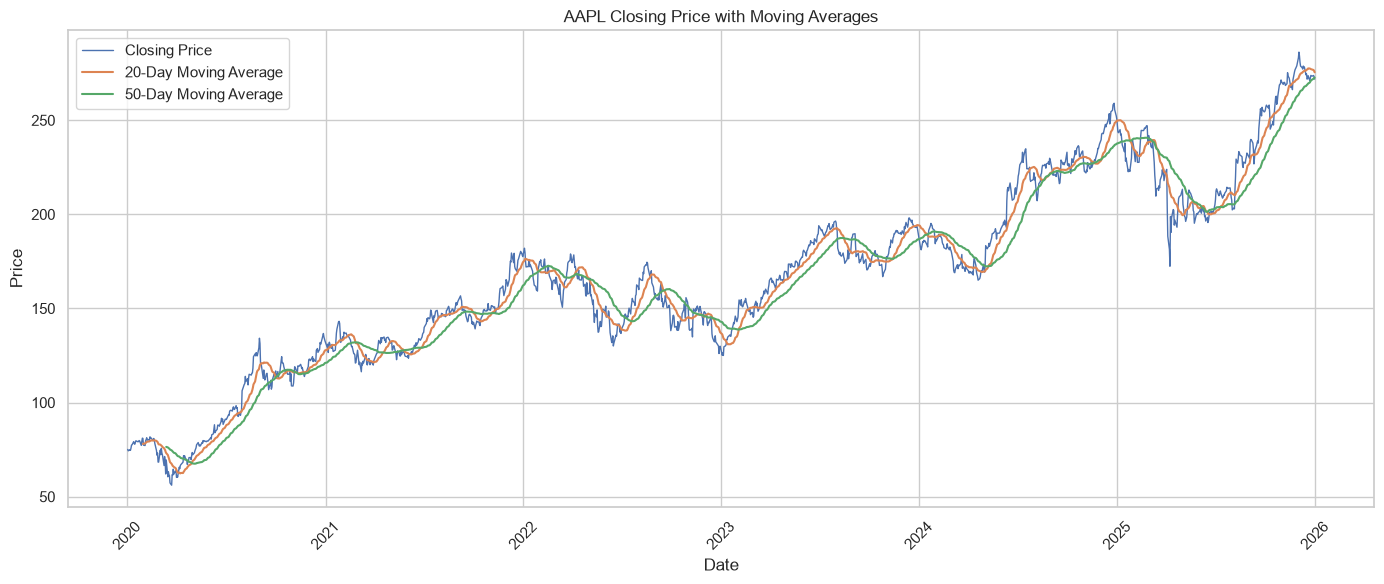

In [101]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"],
    label="Closing Price",
    linewidth=1
)

plt.plot(
    df["Date"],
    df["MA20"],
    label="20-Day Moving Average",
    linewidth=1.5
)

plt.plot(
    df["Date"],
    df["MA50"],
    label="50-Day Moving Average",
    linewidth=1.5
)

plt.title("AAPL Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [102]:
last_valid = df.dropna(subset=["MA20", "MA50"]).iloc[-1]

print("Latest Closing Price:", round(last_valid["Close"], 2))
print("Latest 20-Day Moving Average:", round(last_valid["MA20"], 2))
print("Latest 50-Day Moving Average:", round(last_valid["MA50"], 2))

if last_valid["Close"] > last_valid["MA20"]:
    print("At the end of the period, the closing price was above the 20-day moving average.")
else:
    print("At the end of the period, the closing price was below the 20-day moving average.")

if last_valid["Close"] > last_valid["MA50"]:
    print("At the end of the period, the closing price was above the 50-day moving average.")
else:
    print("At the end of the period, the closing price was below the 50-day moving average.")

Latest Closing Price: 271.86
Latest 20-Day Moving Average: 275.47
Latest 50-Day Moving Average: 272.66
At the end of the period, the closing price was below the 20-day moving average.
At the end of the period, the closing price was below the 50-day moving average.


## Trading Volume Analysis

Trading volume represents the number of shares traded during a trading day.

Volume is analyzed to identify days with unusually high trading activity.

In [103]:
top_volume = df.sort_values(
    "Volume",
    ascending=False
).head(10)

print(top_volume[["Date", "Volume", "Close"]])

          Date     Volume       Close
39  2020-02-28  426510000   68.339996
48  2020-03-12  418474000   62.057499
54  2020-03-20  401693200   57.310001
146 2020-07-31  374336800  106.260002
49  2020-03-13  370732000   69.492500
162 2020-08-24  345937600  125.857498
40  2020-03-02  341397200   74.702499
161 2020-08-21  338054800  124.370003
55  2020-03-23  336752800   56.092499
171 2020-09-04  332607200  120.959999


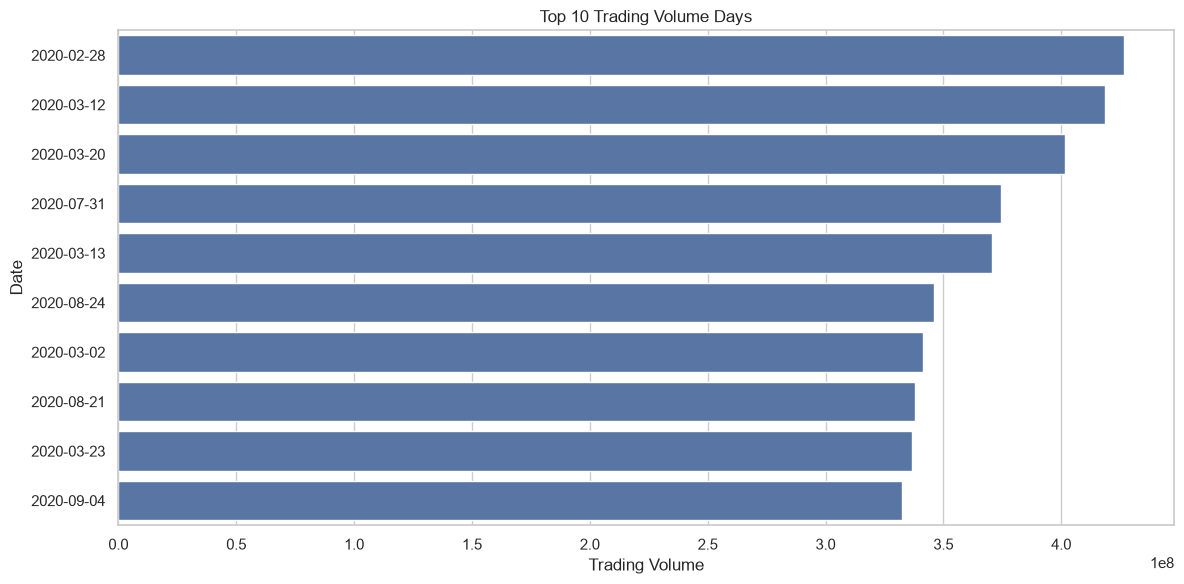

In [104]:
volume_plot_data = top_volume.copy()

volume_plot_data["Date"] = volume_plot_data["Date"].dt.strftime("%Y-%m-%d")

plt.figure(figsize=(12, 6))

sns.barplot(
    x="Volume",
    y="Date",
    data=volume_plot_data
)

plt.title("Top 10 Trading Volume Days")
plt.xlabel("Trading Volume")
plt.ylabel("Date")

plt.tight_layout()
plt.show()

## Daily Return Analysis

Daily return measures the percentage change in the closing price from one trading day to the next.

The daily return is calculated using the percentage change in closing prices.

In [105]:
df["Daily_Return"] = df["Close"].pct_change() * 100

print(df[["Date", "Close", "Daily_Return"]].head(10))

        Date      Close  Daily_Return
0 2020-01-02  75.087502           NaN
1 2020-01-03  74.357498     -0.972204
2 2020-01-06  74.949997      0.796825
3 2020-01-07  74.597504     -0.470305
4 2020-01-08  75.797501      1.608629
5 2020-01-09  77.407501      2.124081
6 2020-01-10  77.582497      0.226070
7 2020-01-13  79.239998      2.136437
8 2020-01-14  78.169998     -1.350328
9 2020-01-15  77.834999     -0.428552


In [106]:
gain_days = (df["Daily_Return"] > 0).sum()
loss_days = (df["Daily_Return"] < 0).sum()
zero_days = (df["Daily_Return"] == 0).sum()

print("Gain Days:", gain_days)
print("Loss Days:", loss_days)
print("Zero Return Days:", zero_days)

Gain Days: 800
Loss Days: 703
Zero Return Days: 4


## Volatility Analysis

Volatility describes how much daily returns vary over time.

The standard deviation of daily returns is used as a basic measure of historical daily volatility.

In [107]:
daily_volatility = df["Daily_Return"].std()
daily_return_variance = df["Daily_Return"].var()

print("Daily Return Standard Deviation:", round(daily_volatility, 4), "%")
print("Daily Return Variance:", round(daily_return_variance, 4))

Daily Return Standard Deviation: 2.0037 %
Daily Return Variance: 4.0147


## Distribution Analysis

The distribution of daily returns is visualized using a histogram.

A KDE curve is added using Seaborn to help visualize the shape of the distribution.

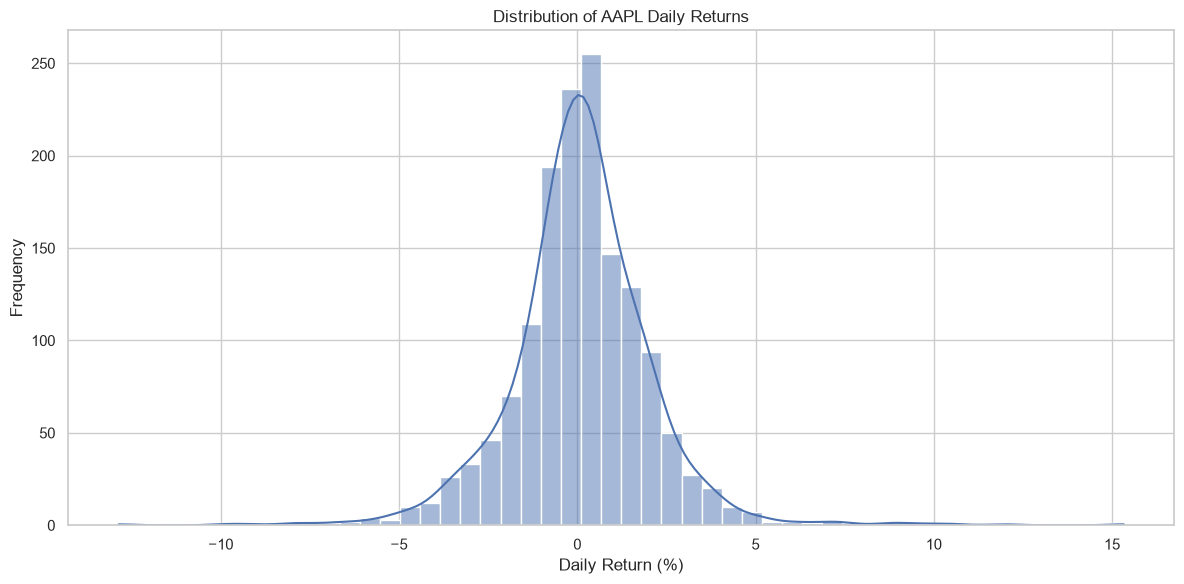

In [108]:
plt.figure(figsize=(12, 6))

sns.histplot(
    df["Daily_Return"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of AAPL Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [109]:
print("Average Daily Return:", round(df["Daily_Return"].mean(), 4), "%")
print("Median Daily Return:", round(df["Daily_Return"].median(), 4), "%")
print("Minimum Daily Return:", round(df["Daily_Return"].min(), 4), "%")
print("Maximum Daily Return:", round(df["Daily_Return"].max(), 4), "%")

Average Daily Return: 0.1054 %
Median Daily Return: 0.1095 %
Minimum Daily Return: -12.8647 %
Maximum Daily Return: 15.3289 %


## Outlier Analysis

A box plot is used to examine the spread of daily returns and identify potential outliers.

The Interquartile Range (IQR) method is also used to calculate the number of observations outside the lower and upper limits.

In [110]:
q1 = df["Daily_Return"].quantile(0.25)
q3 = df["Daily_Return"].quantile(0.75)

iqr = q3 - q1

lower_limit = q1 - (1.5 * iqr)
upper_limit = q3 + (1.5 * iqr)

outliers = df[
    (df["Daily_Return"] < lower_limit) |
    (df["Daily_Return"] > upper_limit)
]

print("Q1:", round(q1, 4))
print("Q3:", round(q3, 4))
print("IQR:", round(iqr, 4))

print("Lower Limit:", round(lower_limit, 4))
print("Upper Limit:", round(upper_limit, 4))

print("Number of Potential Outliers:", len(outliers))

Q1: -0.8225
Q3: 1.1464
IQR: 1.9689
Lower Limit: -3.7759
Upper Limit: 4.0998
Number of Potential Outliers: 68


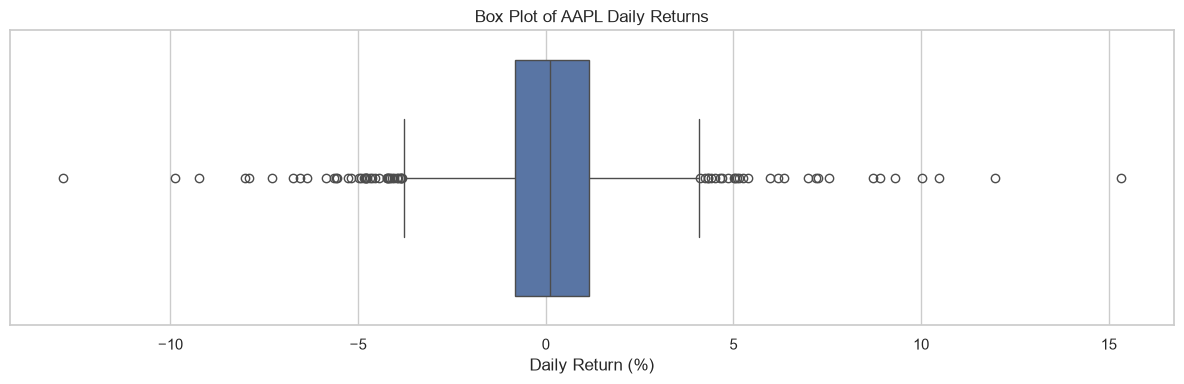

In [111]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=df["Daily_Return"].dropna()
)

plt.title("Box Plot of AAPL Daily Returns")
plt.xlabel("Daily Return (%)")

plt.tight_layout()
plt.show()

## Correlation Analysis

Correlation is used to measure the relationship between numerical variables.

The correlation matrix is visualized using a Seaborn heatmap.

A correlation value close to 1 indicates a positive linear relationship, while a value close to -1 indicates a negative linear relationship. A value near 0 indicates a weak linear relationship.

Correlation does not prove causation.

In [112]:
correlation_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Adj Close",
    "Volume"
]

correlation_columns = [
    column for column in correlation_columns
    if column in df.columns
]

correlation_matrix = df[correlation_columns].corr()

print(correlation_matrix)

               Open      High       Low     Close  Adj Close    Volume
Open       1.000000  0.999341  0.999404  0.998684   0.998606 -0.637022
High       0.999341  1.000000  0.999169  0.999410   0.999344 -0.628689
Low        0.999404  0.999169  1.000000  0.999393   0.999303 -0.644595
Close      0.998684  0.999410  0.999393  1.000000   0.999903 -0.636654
Adj Close  0.998606  0.999344  0.999303  0.999903   1.000000 -0.635549
Volume    -0.637022 -0.628689 -0.644595 -0.636654  -0.635549  1.000000


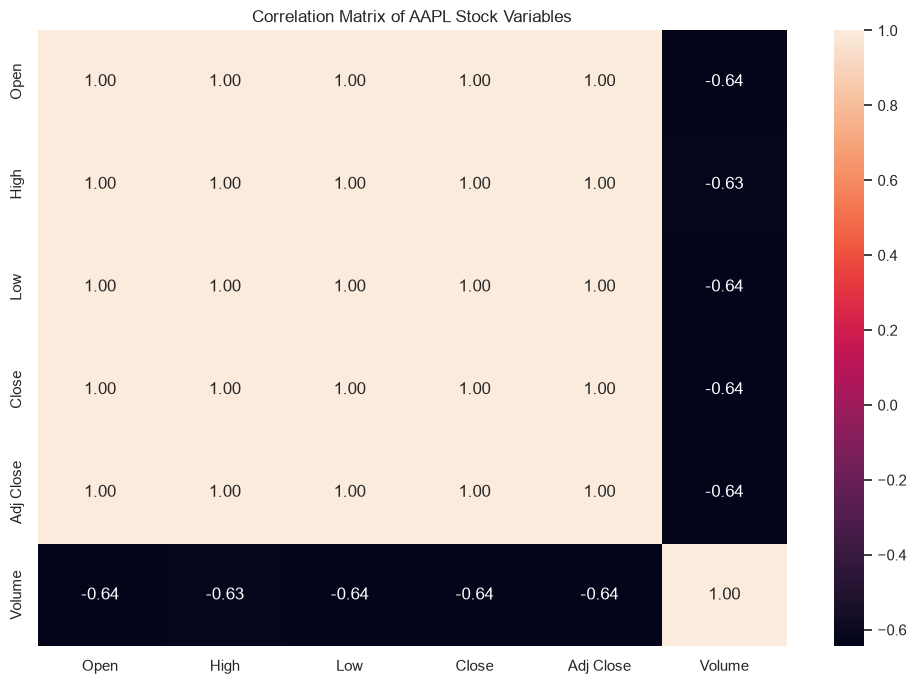

In [113]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix of AAPL Stock Variables")

plt.tight_layout()
plt.show()

## Price vs Volume Analysis

A scatter plot is used to examine the relationship between closing price and trading volume.

The correlation coefficient between closing price and trading volume is also calculated.

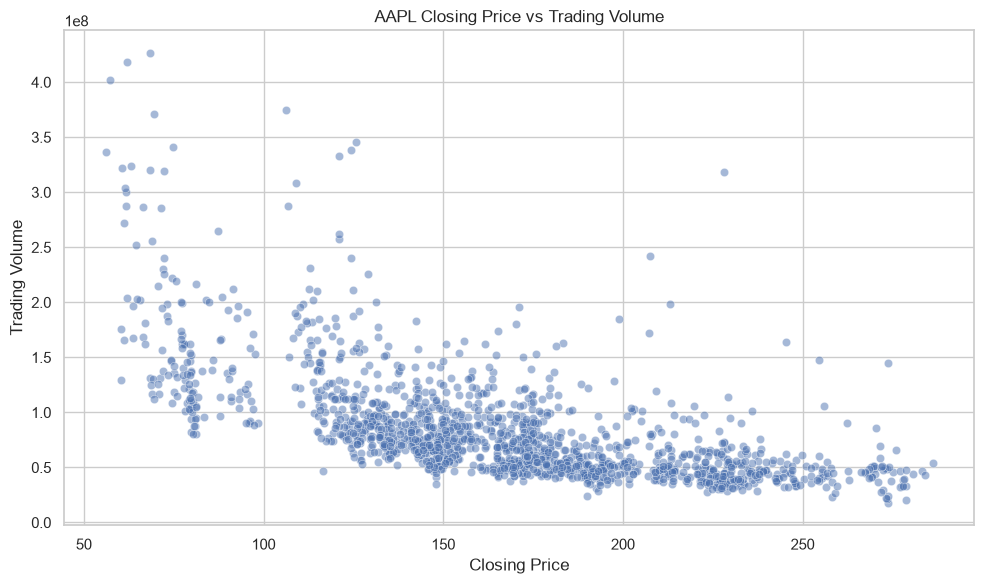

In [114]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="Close",
    y="Volume",
    data=df,
    alpha=0.5
)

plt.title("AAPL Closing Price vs Trading Volume")
plt.xlabel("Closing Price")
plt.ylabel("Trading Volume")

plt.tight_layout()
plt.show()

In [115]:
price_volume_correlation = df["Close"].corr(df["Volume"])

print(
    "Correlation between Closing Price and Trading Volume:",
    round(price_volume_correlation, 4)
)

if price_volume_correlation > 0:
    print("The historical data shows a positive linear correlation between closing price and trading volume.")
elif price_volume_correlation < 0:
    print("The historical data shows a negative linear correlation between closing price and trading volume.")
else:
    print("The historical data shows approximately no linear correlation between closing price and trading volume.")

Correlation between Closing Price and Trading Volume: -0.6367
The historical data shows a negative linear correlation between closing price and trading volume.


## Important Market Events

Important observations are identified directly from the dataset.

The analysis identifies:

- Highest closing price
- Lowest closing price
- Highest trading volume
- Largest daily gain
- Largest daily loss

In [116]:
highest_close = df.loc[df["Close"].idxmax()]
lowest_close = df.loc[df["Close"].idxmin()]
highest_volume = df.loc[df["Volume"].idxmax()]

return_data = df.dropna(subset=["Daily_Return"])

largest_gain = return_data.loc[
    return_data["Daily_Return"].idxmax()
]

largest_loss = return_data.loc[
    return_data["Daily_Return"].idxmin()
]

print("Highest Closing Price")
print("Date:", highest_close["Date"])
print("Close:", round(highest_close["Close"], 2))

print("\nLowest Closing Price")
print("Date:", lowest_close["Date"])
print("Close:", round(lowest_close["Close"], 2))

print("\nHighest Trading Volume")
print("Date:", highest_volume["Date"])
print("Volume:", int(highest_volume["Volume"]))

print("\nLargest Daily Gain")
print("Date:", largest_gain["Date"])
print("Return:", round(largest_gain["Daily_Return"], 2), "%")

print("\nLargest Daily Loss")
print("Date:", largest_loss["Date"])
print("Return:", round(largest_loss["Daily_Return"], 2), "%")

Highest Closing Price
Date: 2025-12-02 00:00:00
Close: 286.19

Lowest Closing Price
Date: 2020-03-23 00:00:00
Close: 56.09

Highest Trading Volume
Date: 2020-02-28 00:00:00
Volume: 426510000

Largest Daily Gain
Date: 2025-04-09 00:00:00
Return: 15.33 %

Largest Daily Loss
Date: 2020-03-16 00:00:00
Return: -12.86 %


## Yearly Analysis

The closing price is grouped by year to examine yearly price statistics.

The first and last closing prices of each year are used to calculate the yearly percentage change.

In [117]:
yearly_data = df.groupby("Year")["Close"].agg(
    ["first", "last", "min", "max", "mean"]
)

yearly_data["Return_%"] = (
    (yearly_data["last"] - yearly_data["first"])
    / yearly_data["first"]
) * 100

print(yearly_data.round(2))

       first    last     min     max    mean  Return_%
Year                                                  
2020   75.09  132.69   56.09  136.69   95.35     76.71
2021  129.41  177.57  116.36  180.33  140.99     37.22
2022  182.01  129.93  126.04  182.01  154.84    -28.61
2023  125.07  192.53  125.02  198.11  172.55     53.94
2024  185.64  250.42  165.00  259.02  207.21     34.90
2025  243.85  271.86  172.42  286.19  232.24     11.49


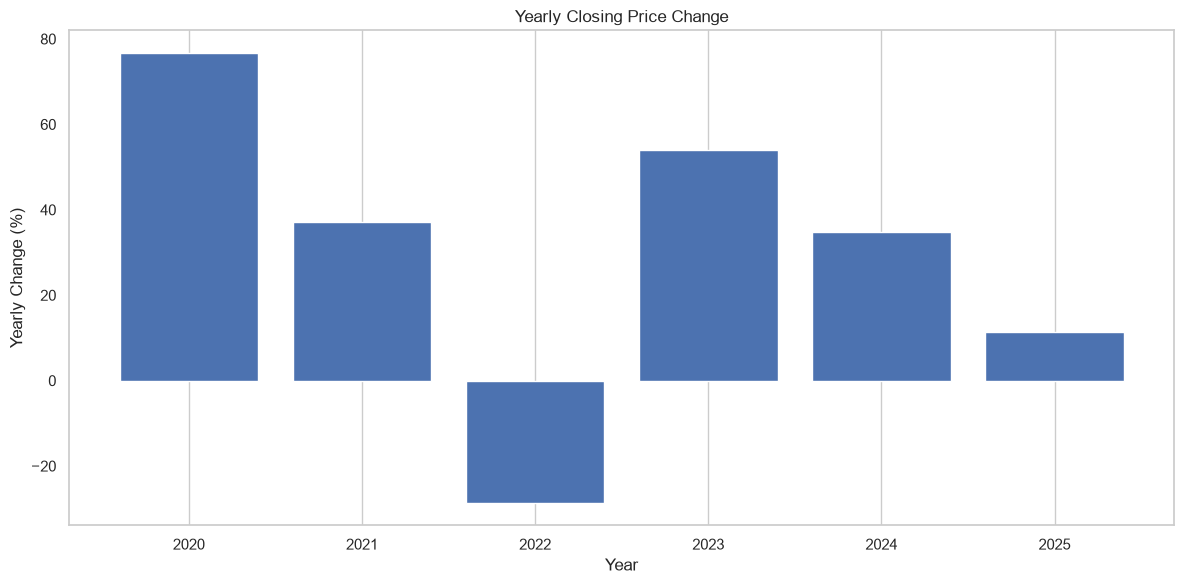

In [118]:
plt.figure(figsize=(12, 6))

plt.bar(
    yearly_data.index.astype(str),
    yearly_data["Return_%"]
)

plt.title("Yearly Closing Price Change")
plt.xlabel("Year")
plt.ylabel("Yearly Change (%)")

plt.grid(axis="y")
plt.tight_layout()
plt.show()

## Monthly Average Closing Price

Monthly average closing prices are calculated to understand how the stock price behaved across different months during the selected period.

In [119]:
monthly_close = df.groupby("Month")["Close"].mean()

print("Monthly Average Closing Price:")
print(monthly_close.round(2))

Monthly Average Closing Price:
Month
1     156.30
2     159.13
3     149.57
4     150.21
5     153.82
6     155.99
7     169.93
8     176.67
9     176.23
10    179.83
11    182.46
12    193.08
Name: Close, dtype: float64


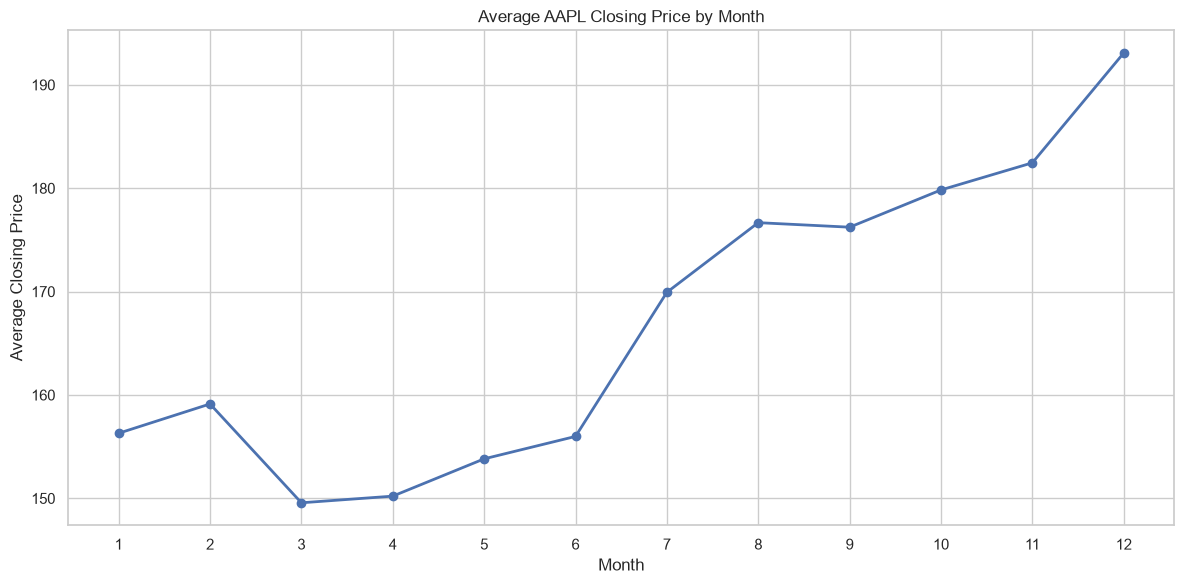

In [120]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_close.index,
    monthly_close.values,
    marker="o",
    linewidth=2
)

plt.title("Average AAPL Closing Price by Month")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.xticks(range(1, 13))
plt.grid(True)

plt.tight_layout()
plt.show()

## Yearly Average Closing Price

The average closing price is calculated for each year to compare the stock price across different years.

In [121]:
yearly_average = df.groupby("Year")["Close"].mean()

print("Yearly Average Closing Price:")
print(yearly_average.round(2))

Yearly Average Closing Price:
Year
2020     95.35
2021    140.99
2022    154.84
2023    172.55
2024    207.21
2025    232.24
Name: Close, dtype: float64


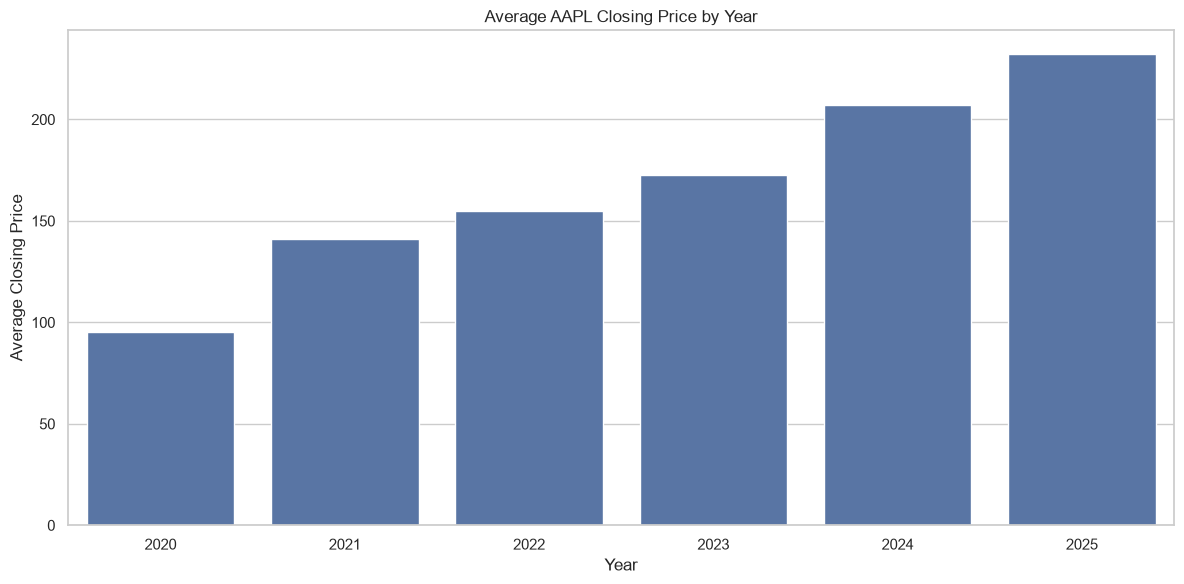

In [122]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=yearly_average.index.astype(str),
    y=yearly_average.values
)

plt.title("Average AAPL Closing Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Closing Price")

plt.tight_layout()
plt.show()

## Yearly Trading Volume Analysis

The total trading volume is calculated for each year to compare trading activity across the selected period.

In [123]:
yearly_volume = df.groupby("Year")["Volume"].sum()

print("Yearly Trading Volume:")
print(yearly_volume)

Yearly Trading Volume:
Year
2020    39863855600
2021    22812206100
2022    22065504500
2023    14805886900
2024    14390908500
2025    13543944600
Name: Volume, dtype: int64


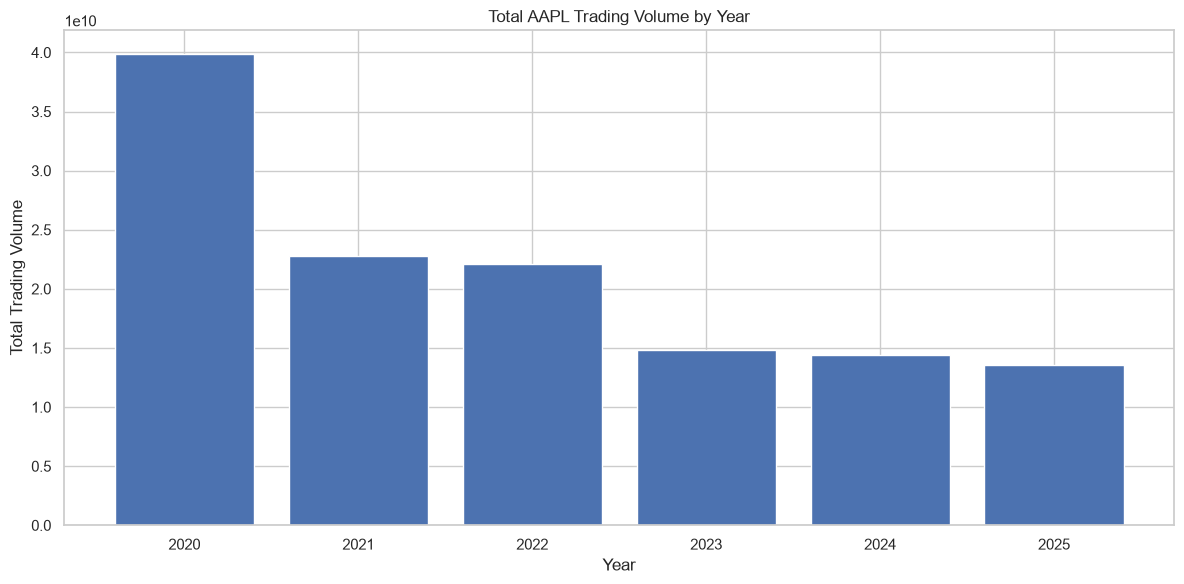

In [124]:
plt.figure(figsize=(12, 6))

plt.bar(
    yearly_volume.index.astype(str),
    yearly_volume.values
)

plt.title("Total AAPL Trading Volume by Year")
plt.xlabel("Year")
plt.ylabel("Total Trading Volume")

plt.tight_layout()
plt.show()

## Monthly Trading Volume Analysis

Monthly trading volume is analyzed to understand how trading activity changes across different months.

In [125]:
monthly_volume = df.groupby("Month")["Volume"].mean()

print("Average Monthly Trading Volume:")
print(monthly_volume.round(0))

Average Monthly Trading Volume:
Month
1      91854530.0
2      85318920.0
3     114999611.0
4      86017673.0
5      85131075.0
6      85718481.0
7      75713331.0
8      81100359.0
9      93574678.0
10     72186216.0
11     68916165.0
12     73502450.0
Name: Volume, dtype: float64


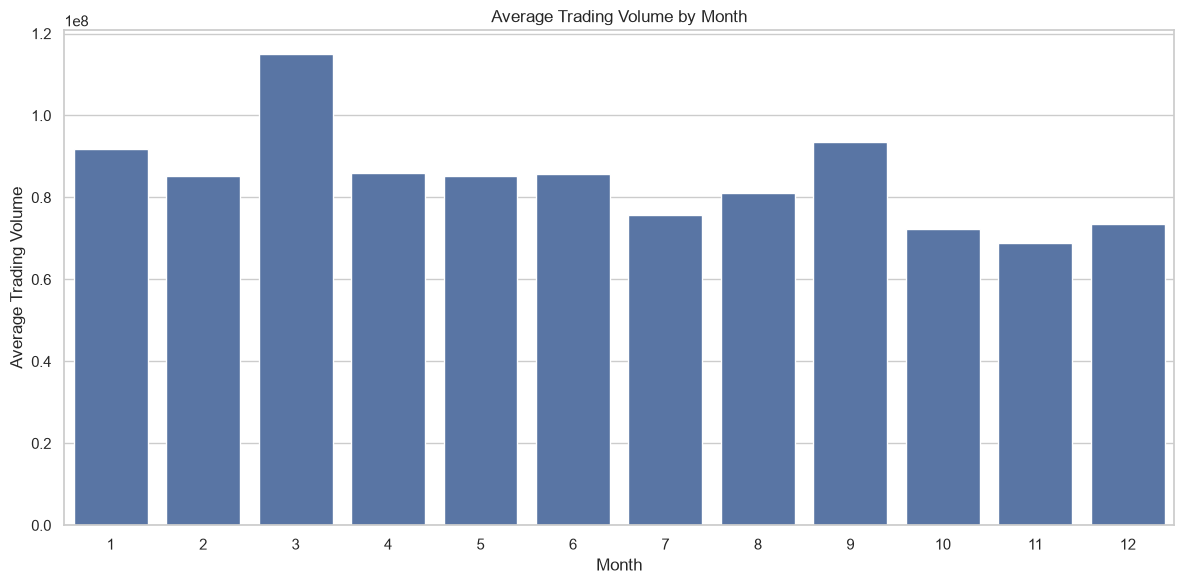

In [126]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_volume.index,
    y=monthly_volume.values
)

plt.title("Average Trading Volume by Month")
plt.xlabel("Month")
plt.ylabel("Average Trading Volume")
plt.xticks(range(0, 12), range(1, 13))

plt.tight_layout()
plt.show()

## Daily Return Trend Analysis

The daily return is plotted over time to observe periods of positive and negative daily price changes.

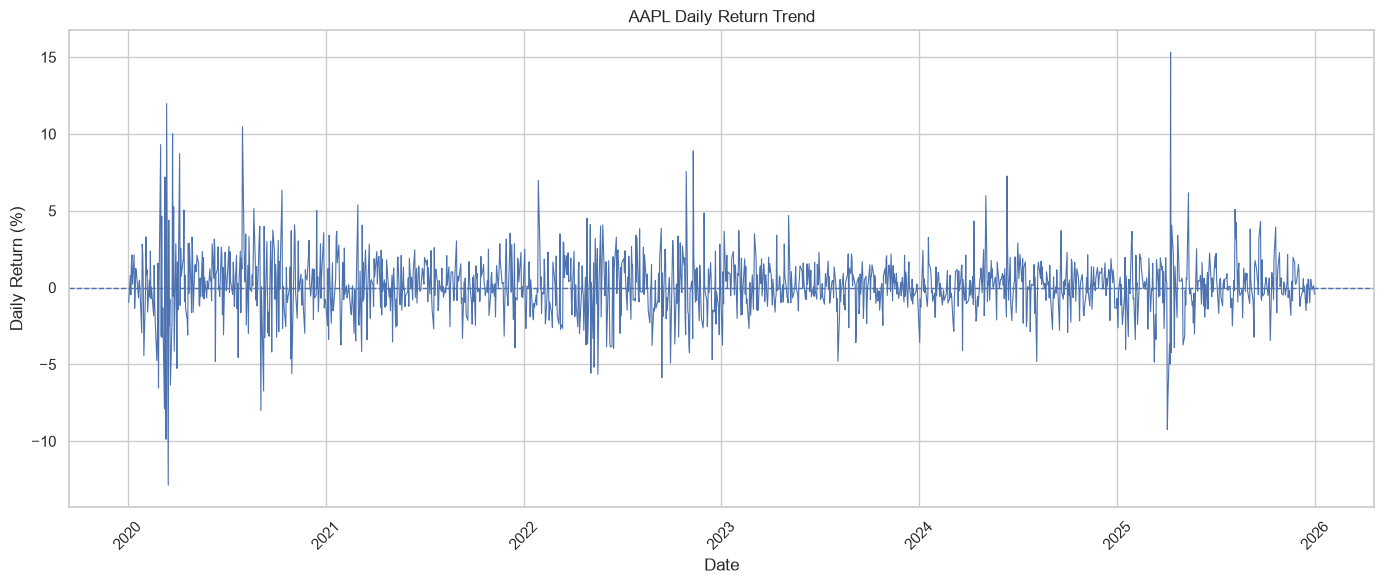

In [127]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Daily_Return"],
    linewidth=0.8
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("AAPL Daily Return Trend")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Positive and Negative Trading Days

Trading days are classified according to whether the daily return was positive, negative, or zero.

In [128]:
positive_days = (df["Daily_Return"] > 0).sum()
negative_days = (df["Daily_Return"] < 0).sum()
zero_days = (df["Daily_Return"] == 0).sum()

print("Positive Trading Days:", positive_days)
print("Negative Trading Days:", negative_days)
print("Zero Return Days:", zero_days)

Positive Trading Days: 800
Negative Trading Days: 703
Zero Return Days: 4


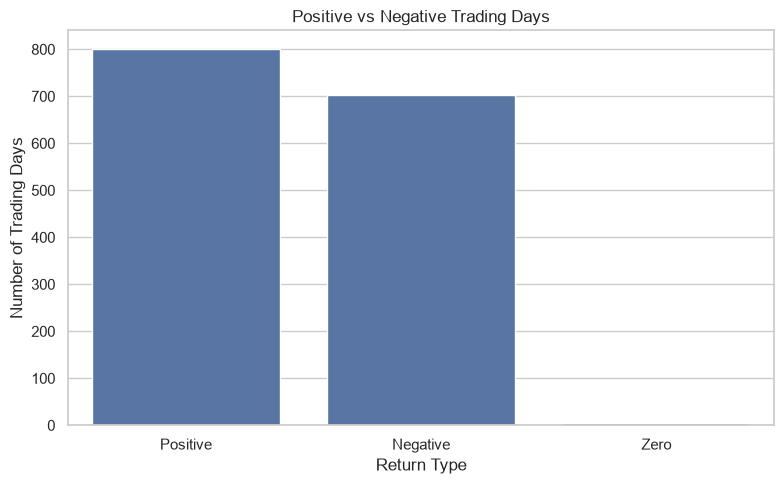

In [129]:
day_types = ["Positive", "Negative", "Zero"]
day_counts = [positive_days, negative_days, zero_days]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=day_types,
    y=day_counts
)

plt.title("Positive vs Negative Trading Days")
plt.xlabel("Return Type")
plt.ylabel("Number of Trading Days")

plt.tight_layout()
plt.show()

## Best and Worst Trading Days

The dates with the largest positive and negative daily returns are identified from the dataset.

In [130]:
best_day = df.loc[df["Daily_Return"].idxmax()]
worst_day = df.loc[df["Daily_Return"].idxmin()]

print("Best Trading Day:")
print("Date:", best_day["Date"])
print("Daily Return:", round(best_day["Daily_Return"], 2), "%")

print("\nWorst Trading Day:")
print("Date:", worst_day["Date"])
print("Daily Return:", round(worst_day["Daily_Return"], 2), "%")

Best Trading Day:
Date: 2025-04-09 00:00:00
Daily Return: 15.33 %

Worst Trading Day:
Date: 2020-03-16 00:00:00
Daily Return: -12.86 %


## Daily High-Low Price Range Analysis

The difference between the daily high and low prices is calculated to understand the daily price range.

In [131]:
df["Daily_Range"] = df["High"] - df["Low"]

print(df[["Date", "High", "Low", "Daily_Range"]].head())

print("\nAverage Daily Price Range:")
print(round(df["Daily_Range"].mean(), 2))

print("\nMaximum Daily Price Range:")
print(round(df["Daily_Range"].max(), 2))

        Date       High        Low  Daily_Range
0 2020-01-02  75.150002  73.797501     1.352501
1 2020-01-03  75.144997  74.125000     1.019997
2 2020-01-06  74.989998  73.187500     1.802498
3 2020-01-07  75.224998  74.370003     0.854996
4 2020-01-08  76.110001  74.290001     1.820000

Average Daily Price Range:
3.58

Maximum Daily Price Range:
28.72


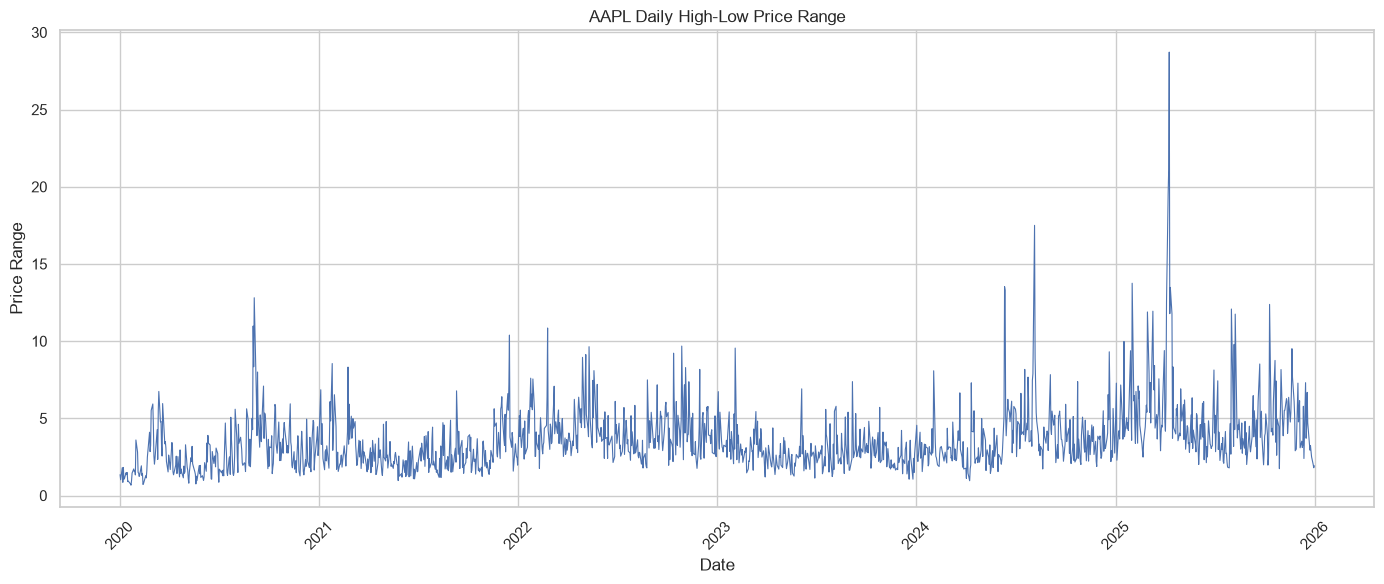

In [132]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Daily_Range"],
    linewidth=0.8
)

plt.title("AAPL Daily High-Low Price Range")
plt.xlabel("Date")
plt.ylabel("Price Range")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Opening vs Closing Price Analysis

Opening and closing prices are compared to understand the daily price movement between the start and end of each trading session.

In [133]:
df["Open_Close_Change"] = df["Close"] - df["Open"]

print(
    df[
        ["Date", "Open", "Close", "Open_Close_Change"]
    ].head(10)
)

        Date       Open      Close  Open_Close_Change
0 2020-01-02  74.059998  75.087502           1.027504
1 2020-01-03  74.287498  74.357498           0.070000
2 2020-01-06  73.447502  74.949997           1.502495
3 2020-01-07  74.959999  74.597504          -0.362495
4 2020-01-08  74.290001  75.797501           1.507500
5 2020-01-09  76.809998  77.407501           0.597504
6 2020-01-10  77.650002  77.582497          -0.067505
7 2020-01-13  77.910004  79.239998           1.329994
8 2020-01-14  79.175003  78.169998          -1.005005
9 2020-01-15  77.962502  77.834999          -0.127502


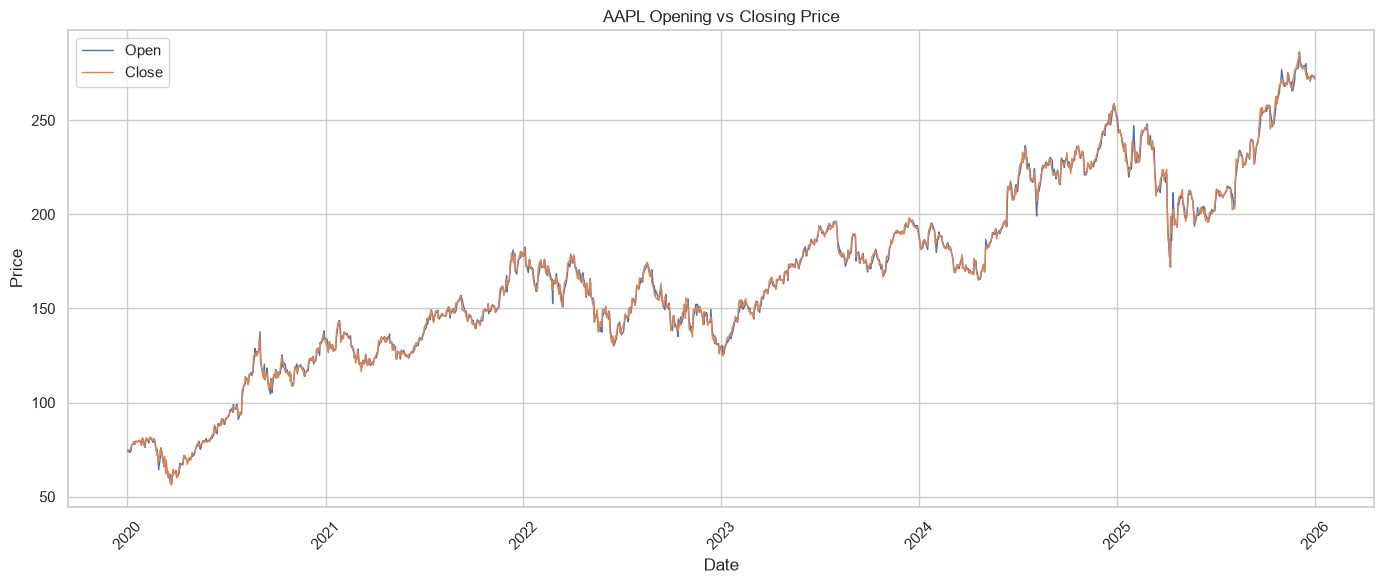

In [134]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Open"],
    label="Open",
    linewidth=1
)

plt.plot(
    df["Date"],
    df["Close"],
    label="Close",
    linewidth=1
)

plt.title("AAPL Opening vs Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Cumulative Return Analysis

Cumulative return shows how the daily percentage changes accumulate over the selected historical period.

This analysis describes historical performance and is not a prediction of future returns.

In [135]:
df["Cumulative_Return"] = (
    (1 + df["Daily_Return"].fillna(0) / 100).cumprod() - 1
) * 100

print(
    df[
        ["Date", "Daily_Return", "Cumulative_Return"]
    ].tail()
)

           Date  Daily_Return  Cumulative_Return
1503 2025-12-24      0.532388         264.654559
1504 2025-12-26     -0.149740         264.108525
1505 2025-12-29      0.131681         264.587986
1506 2025-12-30     -0.248401         263.682345
1507 2025-12-31     -0.446756         262.057573


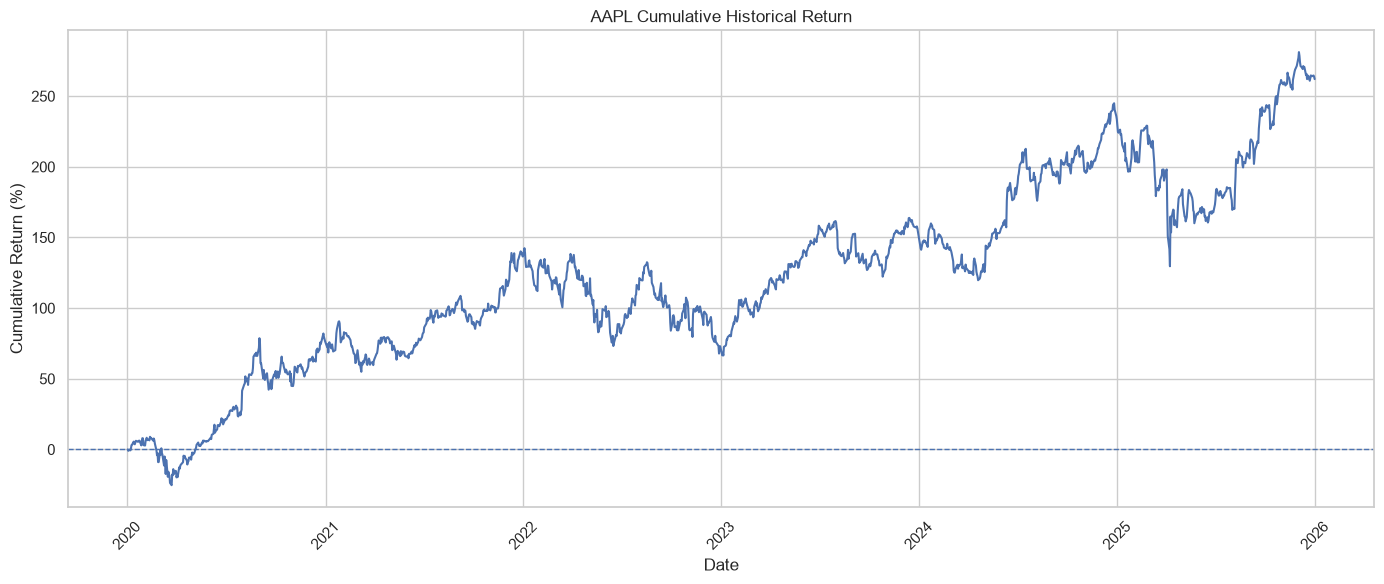

In [136]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Cumulative_Return"],
    linewidth=1.5
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("AAPL Cumulative Historical Return")
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Moving Average Difference Analysis

The difference between the 20-day and 50-day moving averages is calculated to examine how the short-term average compares with the longer-term average.

In [137]:
df["MA_Difference"] = df["MA20"] - df["MA50"]

print(
    df[
        ["Date", "MA20", "MA50", "MA_Difference"]
    ].tail()
)

           Date        MA20        MA50  MA_Difference
1503 2025-12-24  277.151999  271.046599       6.105400
1504 2025-12-26  276.944499  271.527799       5.416700
1505 2025-12-29  276.689999  272.053999       4.636000
1506 2025-12-30  276.188998  272.469799       3.719199
1507 2025-12-31  275.472498  272.662199       2.810298


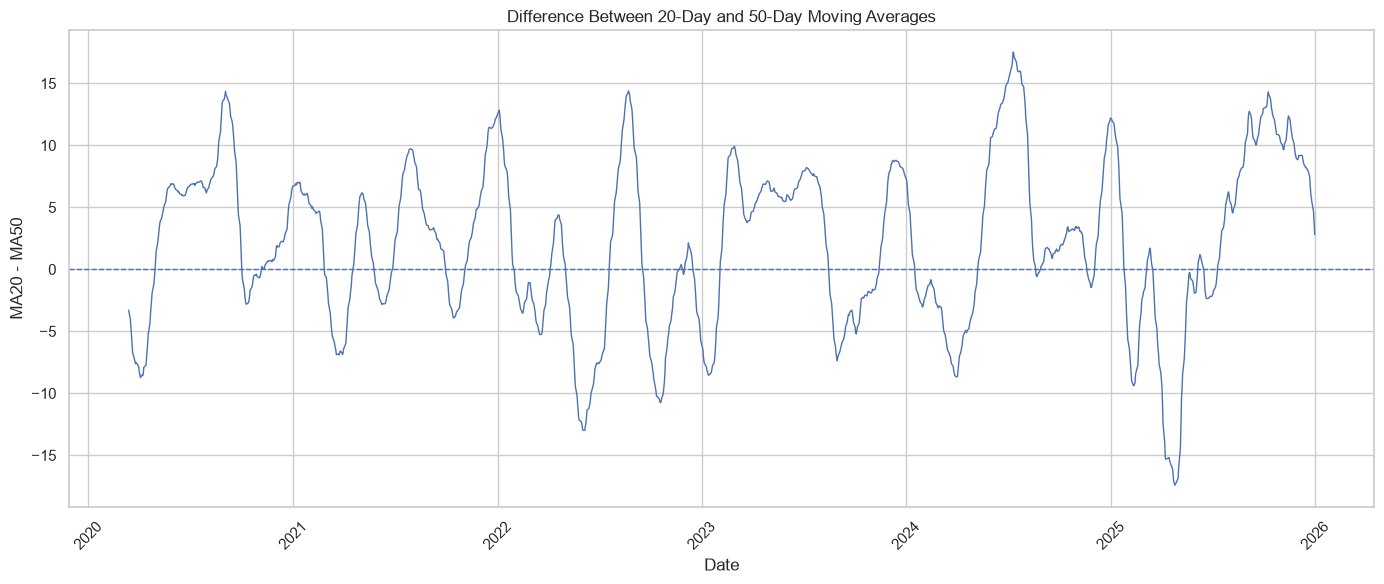

In [138]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["MA_Difference"],
    linewidth=1
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Difference Between 20-Day and 50-Day Moving Averages")
plt.xlabel("Date")
plt.ylabel("MA20 - MA50")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Monthly Return Analysis

Monthly returns are calculated from the first and last closing prices of each month.

This helps compare historical monthly price changes.

In [139]:
df["Year_Month"] = df["Date"].dt.to_period("M")

monthly_price = df.groupby("Year_Month")["Close"].agg(
    ["first", "last"]
)

monthly_price["Monthly_Return_%"] = (
    (monthly_price["last"] - monthly_price["first"])
    / monthly_price["first"]
) * 100

print(monthly_price.head(12).round(2))

             first    last  Monthly_Return_%
Year_Month                                  
2020-01      75.09   77.38              3.05
2020-02      77.17   68.34            -11.44
2020-03      74.70   63.57            -14.90
2020-04      60.23   73.45             21.95
2020-05      72.27   79.49              9.99
2020-06      80.46   91.20             13.34
2020-07      91.03  106.26             16.73
2020-08     108.94  129.04             18.45
2020-09     134.18  115.81            -13.69
2020-10     116.79  108.86             -6.79
2020-11     108.77  119.05              9.45
2020-12     122.72  132.69              8.12


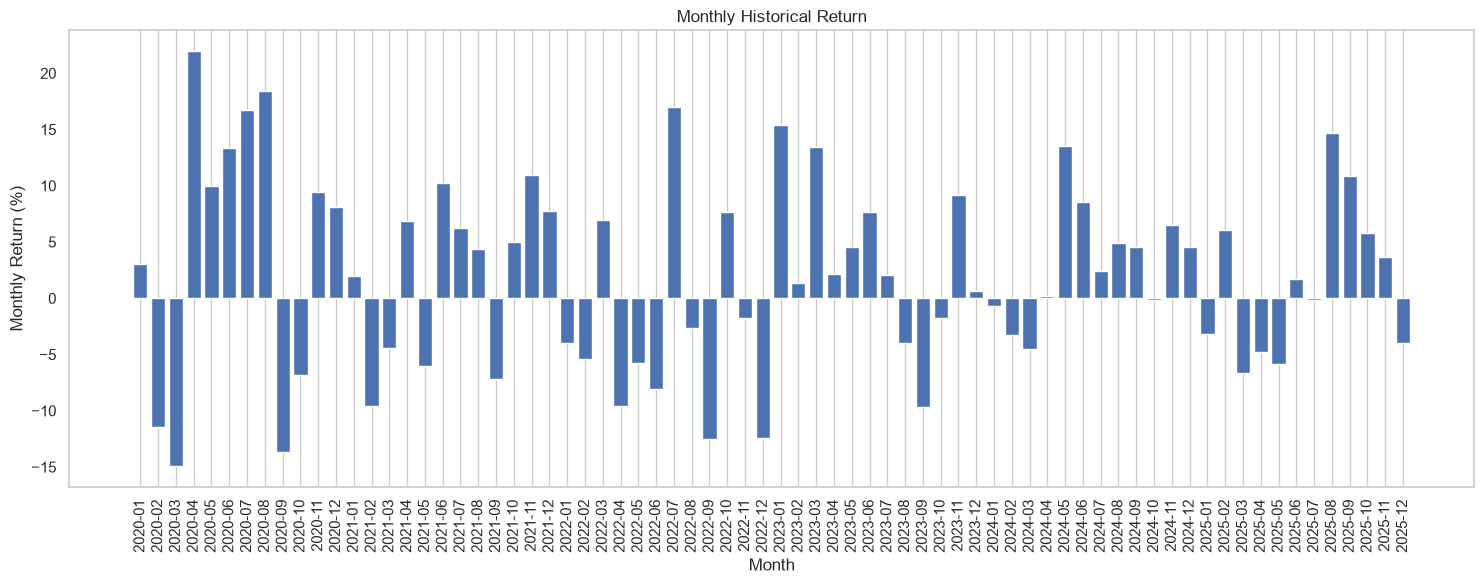

In [140]:
plt.figure(figsize=(15, 6))

plt.bar(
    monthly_price.index.astype(str),
    monthly_price["Monthly_Return_%"]
)

plt.title("Monthly Historical Return")
plt.xlabel("Month")
plt.ylabel("Monthly Return (%)")

plt.xticks(rotation=90)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

## Quarterly Analysis

The dataset is divided into quarters to examine historical closing-price changes across three-month periods.

In [141]:
df["Quarter"] = df["Date"].dt.to_period("Q")

quarterly_price = df.groupby("Quarter")["Close"].agg(
    ["first", "last", "mean", "min", "max"]
)

quarterly_price["Return_%"] = (
    (quarterly_price["last"] - quarterly_price["first"])
    / quarterly_price["first"]
) * 100

print(quarterly_price.round(2))

          first    last    mean     min     max  Return_%
Quarter                                                  
2020Q1    75.09   63.57   73.54   56.09   81.80    -15.34
2020Q2    60.23   91.20   77.49   60.23   91.63     51.43
2020Q3    91.03  115.81  109.12   91.03  134.18     27.23
2020Q4   116.79  132.69  120.28  108.77  136.69     13.61
2021Q1   129.41  122.15  128.36  116.36  143.16     -5.61
2021Q2   123.00  136.96  129.57  122.77  136.96     11.35
2021Q3   137.27  141.50  147.22  137.27  156.69      3.08
2021Q4   142.65  177.57  158.04  139.14  180.33     24.48
2022Q1   182.01  174.61  168.16  150.62  182.01     -4.07
2022Q2   174.31  136.72  151.44  130.06  178.44    -21.57
2022Q3   138.93  138.20  156.95  138.20  174.55     -0.53
2022Q4   142.45  129.93  142.91  126.04  155.74     -8.79
2023Q1   125.07  164.90  147.55  125.02  164.90     31.85
2023Q2   166.17  193.97  174.25  160.10  193.97     16.73
2023Q3   192.46  171.21  183.38  170.43  196.45    -11.04
2023Q4   173.7

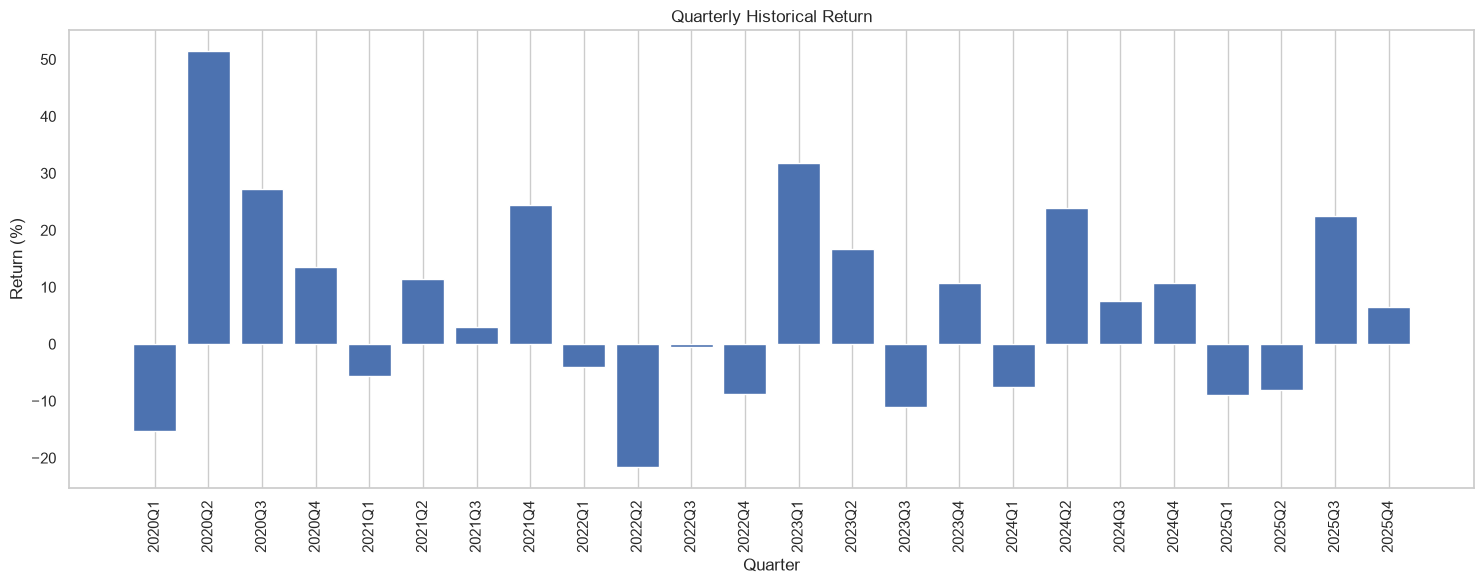

In [142]:
plt.figure(figsize=(15, 6))

plt.bar(
    quarterly_price.index.astype(str),
    quarterly_price["Return_%"]
)

plt.title("Quarterly Historical Return")
plt.xlabel("Quarter")
plt.ylabel("Return (%)")

plt.xticks(rotation=90)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

## Rolling Volatility Analysis

A 20-day rolling standard deviation of daily returns is calculated to observe how historical daily volatility changed over time.

In [143]:
df["Rolling_Volatility_20"] = (
    df["Daily_Return"].rolling(window=20).std()
)

print(
    df[
        ["Date", "Daily_Return", "Rolling_Volatility_20"]
    ].tail()
)

           Date  Daily_Return  Rolling_Volatility_20
1503 2025-12-24      0.532388               0.790661
1504 2025-12-26     -0.149740               0.788430
1505 2025-12-29      0.131681               0.779824
1506 2025-12-30     -0.248401               0.681327
1507 2025-12-31     -0.446756               0.613996


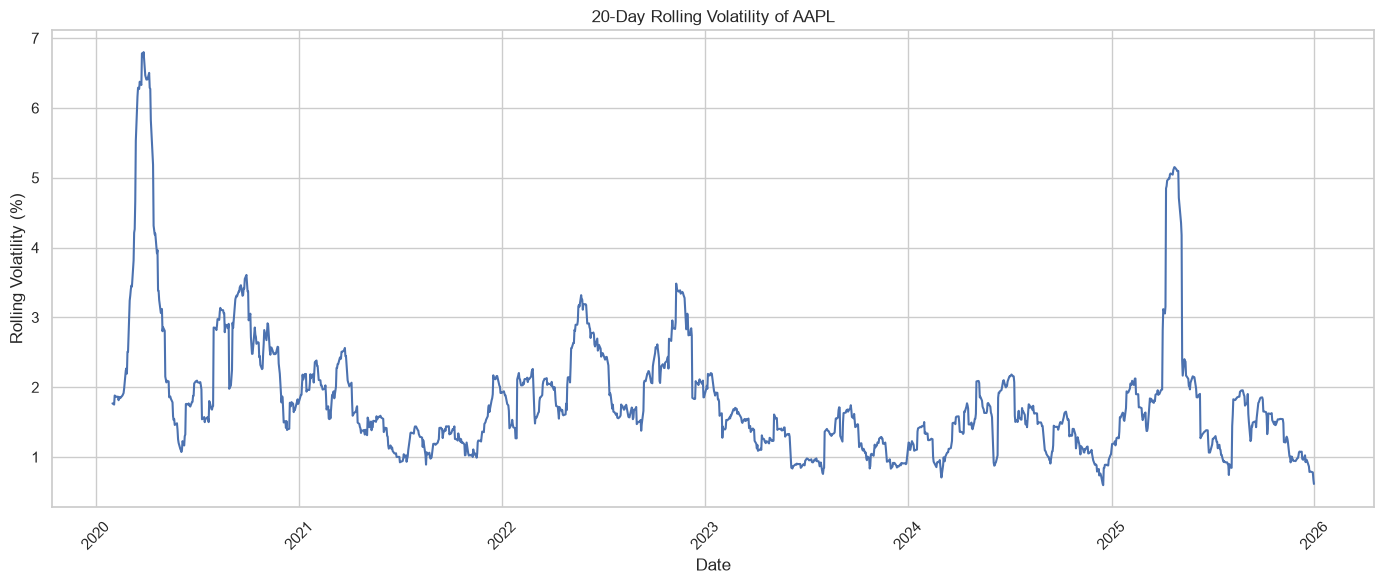

In [144]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Rolling_Volatility_20"],
    linewidth=1.5
)

plt.title("20-Day Rolling Volatility of AAPL")
plt.xlabel("Date")
plt.ylabel("Rolling Volatility (%)")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Trading Volume Distribution

The distribution of trading volume is visualized using a histogram to understand the spread of daily trading activity.

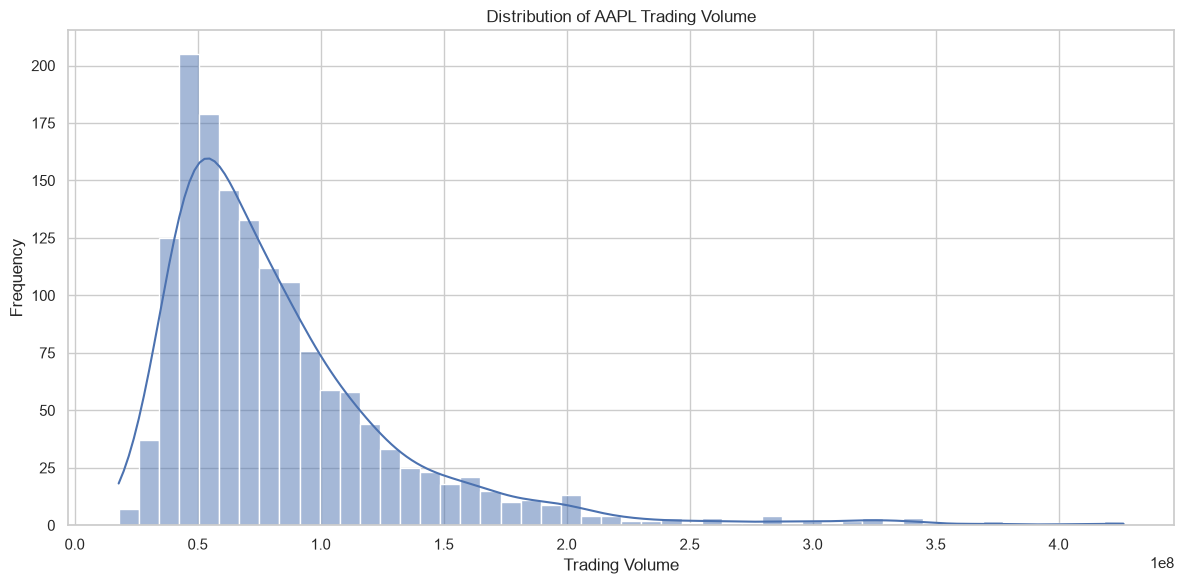

In [145]:
plt.figure(figsize=(12, 6))

sns.histplot(
    df["Volume"],
    bins=50,
    kde=True
)

plt.title("Distribution of AAPL Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Trading Volume Outlier Analysis

A box plot is used to examine the spread of trading volume and identify potential unusually high-volume observations.

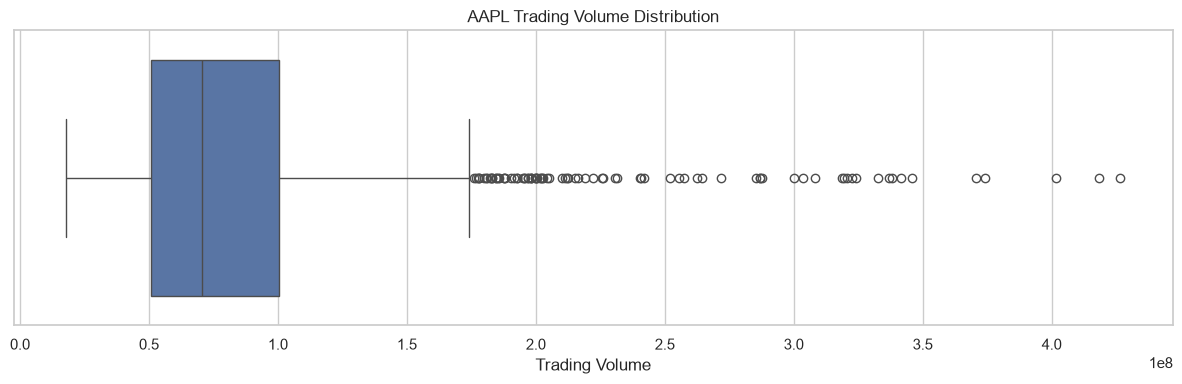

In [146]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=df["Volume"]
)

plt.title("AAPL Trading Volume Distribution")
plt.xlabel("Trading Volume")

plt.tight_layout()
plt.show()

## Statistical Summary of Stock Variables

A statistical summary is created for the main stock price and trading volume variables.

In [147]:
summary_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return"
]

summary_columns = [
    column for column in summary_columns
    if column in df.columns
]

summary = df[summary_columns].describe()

print(summary.round(2))

          Open     High      Low    Close        Volume  Daily_Return
count  1508.00  1508.00  1508.00  1508.00  1.508000e+03       1507.00
mean    166.90   168.77   165.19   167.06  8.453734e+07          0.11
std      48.93    49.25    48.65    48.98  5.136424e+07          2.00
min      57.02    57.12    53.15    56.09  1.791060e+07        -12.86
25%     134.80   136.00   133.33   134.67  5.075645e+07         -0.82
50%     166.05   167.87   164.51   166.08  7.040210e+07          0.11
75%     197.80   200.13   195.91   198.22  1.005718e+08          1.15
max     286.20   288.62   283.30   286.19  4.265100e+08         15.33


## Combined Stock Market Analysis

Multiple important stock indicators are visualized together to provide a compact overview of historical price, volume, and daily return behavior.

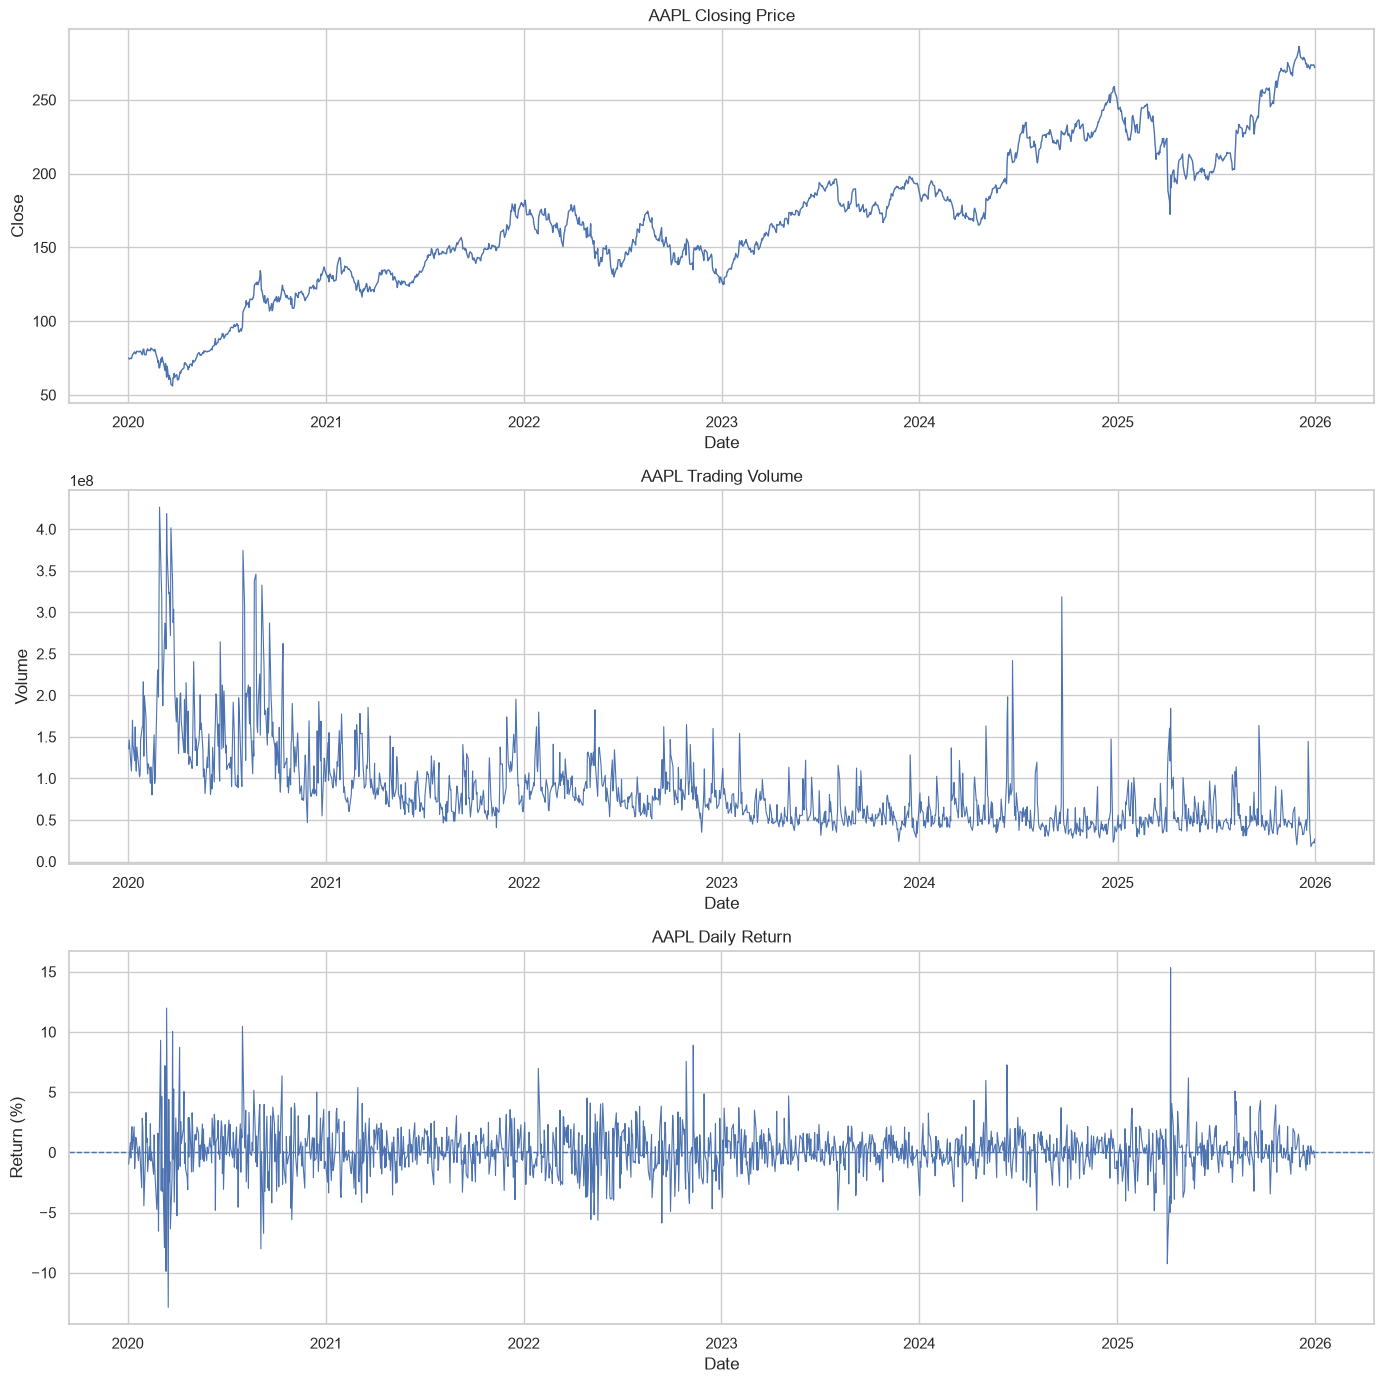

In [148]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# Closing Price
axes[0].plot(
    df["Date"],
    df["Close"],
    linewidth=1
)

axes[0].set_title("AAPL Closing Price")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Close")
axes[0].grid(True)

# Trading Volume
axes[1].plot(
    df["Date"],
    df["Volume"],
    linewidth=0.8
)

axes[1].set_title("AAPL Trading Volume")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Volume")
axes[1].grid(True)

# Daily Return
axes[2].plot(
    df["Date"],
    df["Daily_Return"],
    linewidth=0.8
)

axes[2].axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

axes[2].set_title("AAPL Daily Return")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Return (%)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

## Overall Analysis Summary

The following summary combines the major numerical results obtained during the analysis.

In [149]:
print("OVERALL ANALYSIS SUMMARY")
print("=" * 60)

print("Stock:", ticker)
print("Analysis Period:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Total Trading Days:", len(df))

print("\nPRICE")
print("Starting Close:", round(first_close, 2))
print("Ending Close:", round(last_close, 2))
print("Overall Change (%):", round(percentage_change, 2))

print("\nRETURNS")
print("Average Daily Return (%):", round(df["Daily_Return"].mean(), 4))
print("Best Daily Return (%):", round(df["Daily_Return"].max(), 2))
print("Worst Daily Return (%):", round(df["Daily_Return"].min(), 2))

print("\nVOLATILITY")
print("Daily Volatility (%):", round(daily_volatility, 4))

print("\nVOLUME")
print("Highest Volume:", int(df["Volume"].max()))
print("Average Volume:", int(df["Volume"].mean()))

print("\nPRICE RANGE")
print("Average Daily Range:", round(df["Daily_Range"].mean(), 2))
print("Maximum Daily Range:", round(df["Daily_Range"].max(), 2))

print("\nCORRELATION")
print(
    "Price-Volume Correlation:",
    round(price_volume_correlation, 4)
)

print("\nOUTLIERS")
print("Potential Daily Return Outliers:", len(outliers))

OVERALL ANALYSIS SUMMARY
Stock: AAPL
Analysis Period: 2020-01-02 to 2025-12-31
Total Trading Days: 1508

PRICE
Starting Close: 75.09
Ending Close: 271.86
Overall Change (%): 262.06

RETURNS
Average Daily Return (%): 0.1054
Best Daily Return (%): 15.33
Worst Daily Return (%): -12.86

VOLATILITY
Daily Volatility (%): 2.0037

VOLUME
Highest Volume: 426510000
Average Volume: 84537338

PRICE RANGE
Average Daily Range: 3.58
Maximum Daily Range: 28.72

CORRELATION
Price-Volume Correlation: -0.6367

OUTLIERS
Potential Daily Return Outliers: 68


## Key Findings

The following findings summarize the major observations obtained from the historical AAPL stock data analysis.

The findings are based on the calculated values and visualizations generated in this project.

In [150]:
print("KEY FINDINGS")
print("=" * 70)

# 1. Dataset
print("\n1. DATASET")
print(
    "The dataset contains",
    len(df),
    "trading days from",
    df["Date"].min().strftime("%Y-%m-%d"),
    "to",
    df["Date"].max().strftime("%Y-%m-%d"),
    "."
)

# 2. Overall price movement
print("\n2. OVERALL PRICE MOVEMENT")

if percentage_change > 0:
    print(
        "The closing price increased from",
        round(first_close, 2),
        "to",
        round(last_close, 2),
        "during the selected period."
    )
elif percentage_change < 0:
    print(
        "The closing price decreased from",
        round(first_close, 2),
        "to",
        round(last_close, 2),
        "during the selected period."
    )
else:
    print(
        "There was no net change between the starting and ending "
        "closing prices."
    )

print(
    "Overall percentage change:",
    round(percentage_change, 2),
    "%"
)

# 3. Highest and lowest prices
print("\n3. PRICE EXTREMES")

print(
    "Highest closing price:",
    round(highest_close["Close"], 2),
    "on",
    highest_close["Date"].strftime("%Y-%m-%d")
)

print(
    "Lowest closing price:",
    round(lowest_close["Close"], 2),
    "on",
    lowest_close["Date"].strftime("%Y-%m-%d")
)

# 4. Moving averages
print("\n4. MOVING AVERAGES")

print(
    "Latest closing price:",
    round(last_valid["Close"], 2)
)

print(
    "Latest 20-day moving average:",
    round(last_valid["MA20"], 2)
)

print(
    "Latest 50-day moving average:",
    round(last_valid["MA50"], 2)
)

if last_valid["MA20"] > last_valid["MA50"]:
    print(
        "At the end of the selected period, the 20-day moving average "
        "was above the 50-day moving average."
    )
elif last_valid["MA20"] < last_valid["MA50"]:
    print(
        "At the end of the selected period, the 20-day moving average "
        "was below the 50-day moving average."
    )
else:
    print(
        "At the end of the selected period, the 20-day and 50-day "
        "moving averages were equal."
    )

# 5. Trading volume
print("\n5. TRADING VOLUME")

print(
    "Average daily trading volume:",
    int(df["Volume"].mean())
)

print(
    "Highest trading volume:",
    int(highest_volume["Volume"]),
    "on",
    highest_volume["Date"].strftime("%Y-%m-%d")
)

# 6. Daily returns
print("\n6. DAILY RETURNS")

print(
    "Average daily return:",
    round(df["Daily_Return"].mean(), 4),
    "%"
)

print(
    "Largest daily gain:",
    round(largest_gain["Daily_Return"], 2),
    "% on",
    largest_gain["Date"].strftime("%Y-%m-%d")
)

print(
    "Largest daily loss:",
    round(largest_loss["Daily_Return"], 2),
    "% on",
    largest_loss["Date"].strftime("%Y-%m-%d")
)

# 7. Positive and negative days
print("\n7. TRADING DAY CLASSIFICATION")

print("Positive trading days:", positive_days)
print("Negative trading days:", negative_days)
print("Zero-return days:", zero_days)

# 8. Volatility
print("\n8. VOLATILITY")

print(
    "Standard deviation of daily returns:",
    round(daily_volatility, 4),
    "%"
)

print(
    "20-day rolling volatility was calculated to observe changes "
    "in historical daily return variation over time."
)

# 9. Price range
print("\n9. DAILY PRICE RANGE")

print(
    "Average daily High-Low range:",
    round(df["Daily_Range"].mean(), 2)
)

print(
    "Maximum daily High-Low range:",
    round(df["Daily_Range"].max(), 2)
)

# 10. Price-volume relationship
print("\n10. PRICE AND VOLUME RELATIONSHIP")

print(
    "Correlation between closing price and trading volume:",
    round(price_volume_correlation, 4)
)

if price_volume_correlation > 0:
    print(
        "The calculated correlation indicates a positive linear "
        "relationship between closing price and trading volume."
    )
elif price_volume_correlation < 0:
    print(
        "The calculated correlation indicates a negative linear "
        "relationship between closing price and trading volume."
    )
else:
    print(
        "The calculated correlation indicates approximately no "
        "linear relationship between closing price and trading volume."
    )

# 11. Outliers
print("\n11. OUTLIER ANALYSIS")

print(
    "The IQR method identified",
    len(outliers),
    "potential outliers in daily returns."
)

# 12. Cumulative return
print("\n12. CUMULATIVE RETURN")

final_cumulative_return = df["Cumulative_Return"].iloc[-1]

print(
    "Final cumulative historical return:",
    round(final_cumulative_return, 2),
    "%"
)

print("\n" + "=" * 70)

KEY FINDINGS

1. DATASET
The dataset contains 1508 trading days from 2020-01-02 to 2025-12-31 .

2. OVERALL PRICE MOVEMENT
The closing price increased from 75.09 to 271.86 during the selected period.
Overall percentage change: 262.06 %

3. PRICE EXTREMES
Highest closing price: 286.19 on 2025-12-02
Lowest closing price: 56.09 on 2020-03-23

4. MOVING AVERAGES
Latest closing price: 271.86
Latest 20-day moving average: 275.47
Latest 50-day moving average: 272.66
At the end of the selected period, the 20-day moving average was above the 50-day moving average.

5. TRADING VOLUME
Average daily trading volume: 84537338
Highest trading volume: 426510000 on 2020-02-28

6. DAILY RETURNS
Average daily return: 0.1054 %
Largest daily gain: 15.33 % on 2025-04-09
Largest daily loss: -12.86 % on 2020-03-16

7. TRADING DAY CLASSIFICATION
Positive trading days: 800
Negative trading days: 703
Zero-return days: 4

8. VOLATILITY
Standard deviation of daily returns: 2.0037 %
20-day rolling volatility was ca

## Conclusion

The conclusion summarizes the results obtained from the complete historical stock market analysis.

It is based on the actual calculations, statistical analysis, and visualizations performed in this project.

In [151]:
print("CONCLUSION")
print("=" * 70)

print(
    "This project analyzed historical AAPL stock market data using "
    "Python, Pandas, NumPy, Matplotlib, and Seaborn."
)

print(
    "\nThe dataset was first loaded and inspected. "
    "Data cleaning was performed by checking missing values, "
    "duplicate records, data types, and date formatting."
)

print(
    "\nThe exploratory analysis examined the opening, high, low, "
    "closing prices and trading volume."
)

print(
    "\nThe closing-price trend provided an overview of how the "
    "stock price changed throughout the selected historical period."
)

print(
    "\nThe 20-day and 50-day moving averages were calculated to "
    "observe smoothed historical price movements."
)

print(
    "\nTrading volume analysis was performed to identify periods "
    "with higher levels of historical trading activity."
)

print(
    "\nDaily returns were calculated to measure day-to-day changes "
    "in the closing price."
)

print(
    "\nThe standard deviation of daily returns was used as a basic "
    "measure of historical daily volatility."
)

print(
    "\nHistogram and box-plot analysis were used to understand the "
    "distribution of daily returns and identify potential outliers."
)

print(
    "\nCorrelation analysis was used to examine relationships "
    "between numerical stock variables."
)

print(
    "\nThe price-volume analysis calculated the linear correlation "
    "between closing price and trading volume."
)

print(
    "\nYearly, monthly, and quarterly analyses were also performed "
    "to compare historical price changes across different periods."
)

print(
    "\nThe cumulative return analysis provided a historical view "
    "of how daily returns accumulated during the selected period."
)

# Dynamic overall observation
if percentage_change > 0:
    print(
        "\nBased on the selected historical period, the closing price "
        "was higher at the end of the period than at the beginning."
    )
elif percentage_change < 0:
    print(
        "\nBased on the selected historical period, the closing price "
        "was lower at the end of the period than at the beginning."
    )
else:
    print(
        "\nBased on the selected historical period, there was no net "
        "change between the beginning and ending closing prices."
    )

print(
    "\nOverall, the project demonstrates how historical stock market "
    "data can be collected, cleaned, transformed, analyzed, and "
    "visualized using Python."
)

print(
    "\nThe analysis describes historical observations only. "
    "It does not predict future stock prices or provide investment advice."
)

print("\n" + "=" * 70)

CONCLUSION
This project analyzed historical AAPL stock market data using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The dataset was first loaded and inspected. Data cleaning was performed by checking missing values, duplicate records, data types, and date formatting.

The exploratory analysis examined the opening, high, low, closing prices and trading volume.

The closing-price trend provided an overview of how the stock price changed throughout the selected historical period.

The 20-day and 50-day moving averages were calculated to observe smoothed historical price movements.

Trading volume analysis was performed to identify periods with higher levels of historical trading activity.

Daily returns were calculated to measure day-to-day changes in the closing price.

The standard deviation of daily returns was used as a basic measure of historical daily volatility.

Histogram and box-plot analysis were used to understand the distribution of daily returns and identify potential o

## Final Project Summary

This project demonstrates the complete data analysis workflow:

**Data Collection → Data Inspection → Data Cleaning → Preprocessing → Exploratory Data Analysis → Numerical Analysis → Statistical Analysis → Visualization → Findings → Conclusion**

The project uses Pandas for data manipulation, NumPy for numerical calculations, Matplotlib and Seaborn for visualization, and yfinance for obtaining historical Yahoo Finance stock data.